# Etapa 3 · Visualizações

Nesta etapa eu monto visualizações para responder às seis perguntas da atividade. Não recalculo nada pesado: uso as tabelas que salvei no fim do `etapa2_metricas.ipynb` (medidas por artigo, tópicos e vetores dos artigos). Alguns gráficos da Etapa 2 já respondem parte das perguntas; nesses casos eu só faço referência a eles e uso esta etapa para mostrar o que ainda faltava.

In [1]:
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import umap
from matplotlib.colors import LinearSegmentedColormap
from nltk.corpus import stopwords
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.stats import kruskal

warnings.filterwarnings("ignore", message=".*n_jobs value.*")

sns.set_theme(style="whitegrid", rc={
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#666666", "grid.color": "#e6e6e6",
    "axes.labelcolor": "#191919", "xtick.color": "#666666", "ytick.color": "#666666",
})
CORES = {"train": "#257de0", "validation": "#f47230", "test": "#00b894"}
AZUL, LARANJA, CINZA = "#257de0", "#f47230", "#d0d0d0"
DIVERGENTE = LinearSegmentedColormap.from_list("azul_cinza_vermelho", ["#257de0", "#efefef", "#ec4647"])

DATA_DIR = Path("data")
PALAVRA = r"\w+(?:[-.,']\w+)*"

art = pd.read_parquet(DATA_DIR / "metricas_artigos.parquet")
art["split"] = pd.Categorical(art["split"], categories=list(CORES))
V = np.load(DATA_DIR / "vetores_artigos.npy")
topicos = pd.read_parquet(DATA_DIR / "topicos.parquet")
textos = pd.read_parquet(DATA_DIR / "artigos.parquet")["text_limpo"]   # mesma ordem de art
assert len(art) == len(V) == len(textos)

C:\Users\jairoNeto\Desktop\kunumi\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Os tópicos da Etapa 2 vêm só com números e palavras-chave. Para os gráficos ficarem legíveis, dou a cada um o nome que escolhi na Etapa 2, identificando o tópico pela sua primeira palavra-chave.

In [2]:
NOMES = {
    "navy": "História militar", "episodes": "TV e cinema", "album": "Música", "championship": "Esportes",
    "readers": "Literatura", "temple": "Índia e sul da Ásia", "genus": "Biologia", "appointed": "Nobreza e clero",
    "highway": "Estradas (EUA)", "gameplay": "Videogames", "architect": "Arquitetura e igrejas",
    "acres": "Geografia e natureza", "cyclone": "Furacões", "acid": "Ciências exatas",
}
topicos["nome"] = topicos["palavras_chave"].str.split(", ").str[0].map(NOMES)
assert topicos["nome"].notna().all(), "os tópicos da Etapa 2 mudaram: atualize o dicionário NOMES"
K = len(topicos)
nome_de = topicos.set_index("topico")["nome"]
art["tema"] = art["topico"].map(nome_de)

# ordem "por parentesco": tópicos com centros parecidos ficam lado a lado
centros = np.vstack([V[art["topico"] == t].mean(axis=0) for t in range(K)])
centros /= np.linalg.norm(centros, axis=1, keepdims=True)
ORDEM_PARENTESCO = [nome_de[t] for t in leaves_list(linkage(centros, method="average", metric="cosine"))]
ORDEM_TAMANHO = topicos.sort_values("artigos", ascending=False)["nome"].tolist()

topicos[["nome", "artigos", "train", "validation", "test", "palavras_chave"]]

,nome,artigos,train,validation,test,palavras_chave
0,História militar,84,64,8,12,"navy, guns, naval, command, commander, gun, of..."
1,TV e cinema,80,64,10,6,"episodes, episode, viewers, aired, television,..."
2,Música,76,66,6,4,"album, billboard, vocals, chart, songs, lyrics..."
3,Esportes,75,61,6,8,"championship, win, scored, victory, teams, lea..."
4,Literatura,72,60,5,7,"readers, books, publication, literary, describ..."
5,Índia e sul da Ásia,49,43,4,2,"temple, dynasty, ruler, temples, muslim, son, ..."
6,Biologia,42,38,2,2,"genus, species, specimens, epithet, closely, h..."
7,Nobreza e clero,39,33,1,5,"appointed, king, elected, heir, court, earl, b..."
8,Estradas (EUA),39,31,6,2,"highway, intersection, terminus, highways, roa..."
9,Videogames,36,33,1,2,"gameplay, gaming, graphics, playstation, playe..."


## 1. Quais são os assuntos mais frequentes no WikiText-2?

A contagem de artigos por tópico já está no **Gráfico 2.7** da Etapa 2: história militar (84 artigos), TV e cinema (80), música (76), esportes (75) e literatura (72) são os maiores e somam 54% do corpus. Aqui eu complemento mostrando **do que cada tópico fala**, pelas palavras que mais o caracterizam.

**Gráfico 3.1** · Do que cada tópico fala?

Na Etapa 2 eu dei nome aos tópicos lendo as palavras-chave numa tabela. Aqui quis deixar isso visual, para dar para ver de uma vez o vocabulário que caracteriza cada assunto e conferir se os nomes que escolhi fazem sentido.

- cada mini gráfico é um tópico (com o nº de artigos entre parênteses), do maior para o menor. As barras são as 6 palavras com maior peso: palavras que aparecem em muitos artigos do tópico e em poucos artigos fora dele (o mesmo cálculo da Etapa 2).

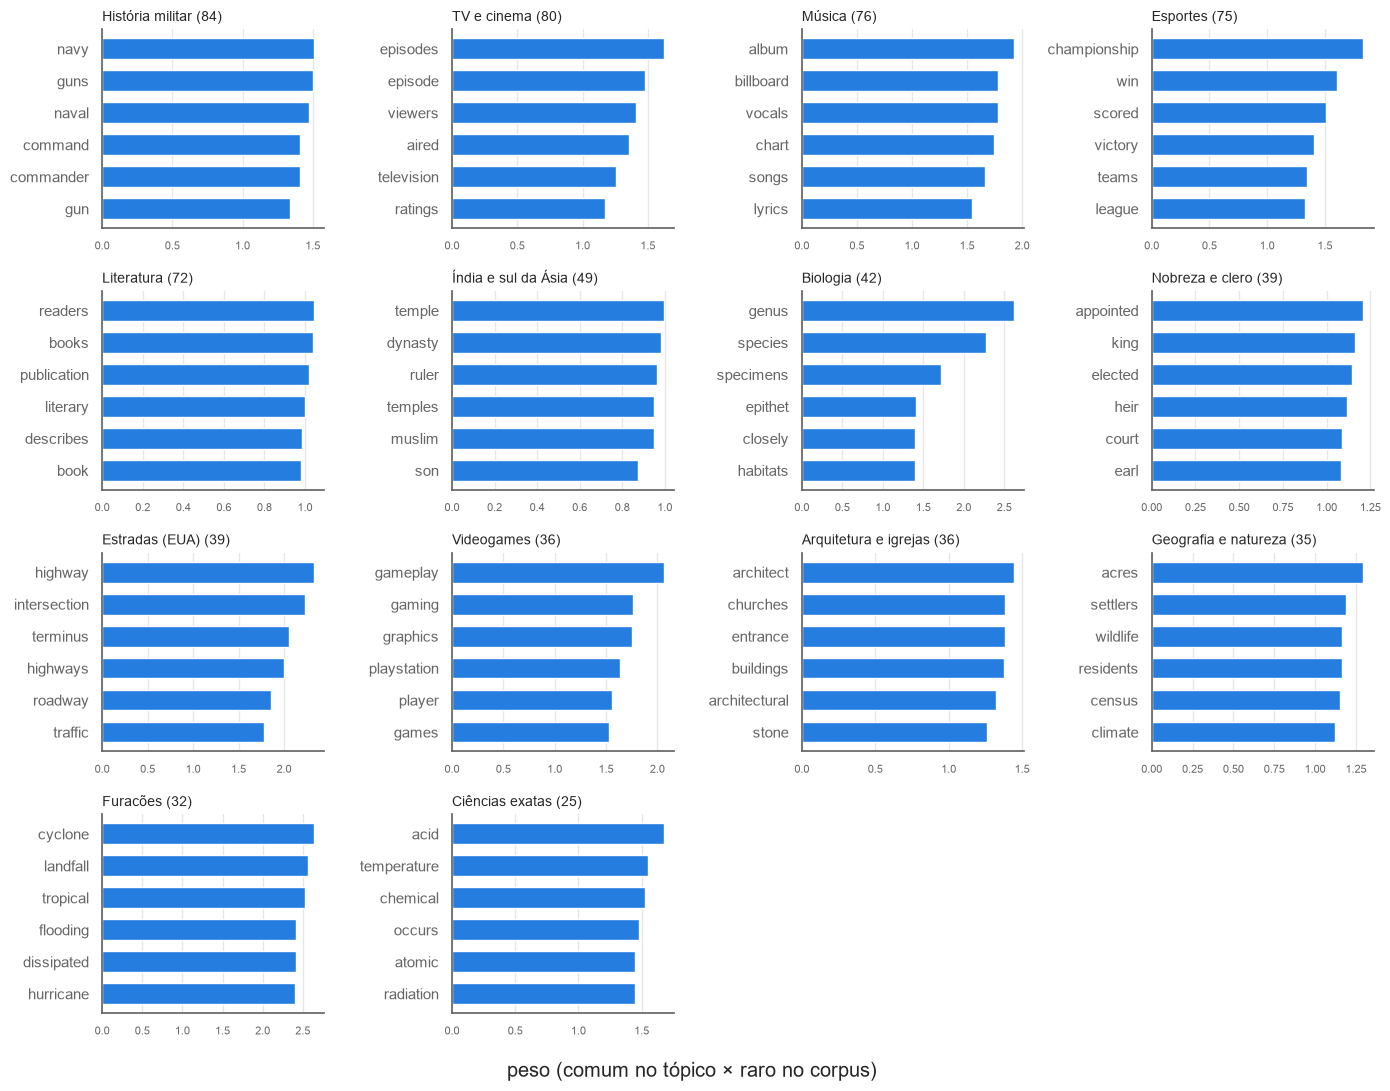

In [3]:
STOP = set(stopwords.words("english"))
conjuntos = textos.str.lower().str.findall(PALAVRA).map(
    lambda ts: {t for t in ts if t.isalpha() and len(t) > 2 and t not in STOP})
n_artigos_com = Counter(t for s in conjuntos for t in s)

def pesos_chave(nome, n=6):
    membros = conjuntos[art["tema"] == nome]
    dentro = Counter(t for s in membros for t in s)
    peso = {t: k / len(membros) * np.log(len(art) / n_artigos_com[t]) for t, k in dentro.items()}
    return pd.Series(peso).nlargest(n)

fig, axes = plt.subplots(4, 4, figsize=(14, 11))
for ax, nome in zip(axes.flat, ORDEM_TAMANHO):
    p = pesos_chave(nome)[::-1]
    ax.barh(p.index, p.values, color=AZUL, height=0.65)
    ax.set_title(f"{nome} ({(art['tema'] == nome).sum()})", loc="left", fontsize=10)
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="y", visible=False)
for ax in axes.flat[K:]:
    ax.set_visible(False)
fig.supxlabel("peso (comum no tópico × raro no corpus)")
plt.tight_layout()
plt.show()

- As palavras confirmam os nomes: `navy`, `guns` e `naval` em história militar; `episodes`, `viewers` e `aired` em TV e cinema; `album`, `billboard` e `vocals` em música; `cyclone`, `landfall` e `tropical` em furacões.
- Nos tópicos mais fechados (furacões, biologia, estradas), as barras são longas: várias palavras aparecem em quase todos os artigos do grupo. Em literatura e Índia as barras são curtas (peso perto de 1), ou seja, nenhuma palavra é compartilhada por quase todos os artigos, sinal de que esses tópicos são mais amplos.
- Os cinco maiores assuntos são de cultura, entretenimento e história. A ciência aparece só em dois tópicos pequenos (biologia e ciências exatas).

## 2. Como os diferentes assuntos estão distribuídos?

O **Gráfico 2.7** mostra o tamanho de cada tópico e a **entropia normalizada** (0,97) resume o equilíbrio num número só. Aqui eu uso a **curva de concentração** (curva de Lorenz, Lorenz, 1905), que mostra esse equilíbrio de forma visual e permite comparar o corpus com cada split.

**Gráfico 3.2** · O quanto os assuntos estão concentrados?

A entropia da Etapa 2 resume o equilíbrio num número só. Aqui quis ver a forma dessa distribuição e comparar o corpus com cada split, já que validation e test têm só 60 artigos.

- cada linha é um grupo de artigos (o corpus inteiro e cada split), sempre com os mesmos 14 tópicos. Os tópicos são ordenados do menor para o maior, e cada ponto é um tópico: o eixo x é quantos tópicos já somei (de 0 a 14), e o eixo y é a fração dos artigos **daquele grupo** que eles somam (dividindo por 720, 600, 60 ou 60). Por exemplo, o ponto 7 da linha do corpus mostra que os 7 menores tópicos têm 34% dos artigos.
- se todos os tópicos tivessem o mesmo tamanho, cada ponto subiria a mesma quantidade (1/14) e a linha seria a reta tracejada. Como os tópicos são ordenados do menor para o maior, os primeiros passos sobem pouco e os últimos sobem muito, e a linha vira uma curva. Quanto mais curvada e afastada da reta, mais concentrada é a distribuição. O **índice de Gini** (Gini, 1912) resume esse afastamento: 0 é igualdade total e 1 é tudo num tópico só (é 1 − 2 × a área sob a curva).

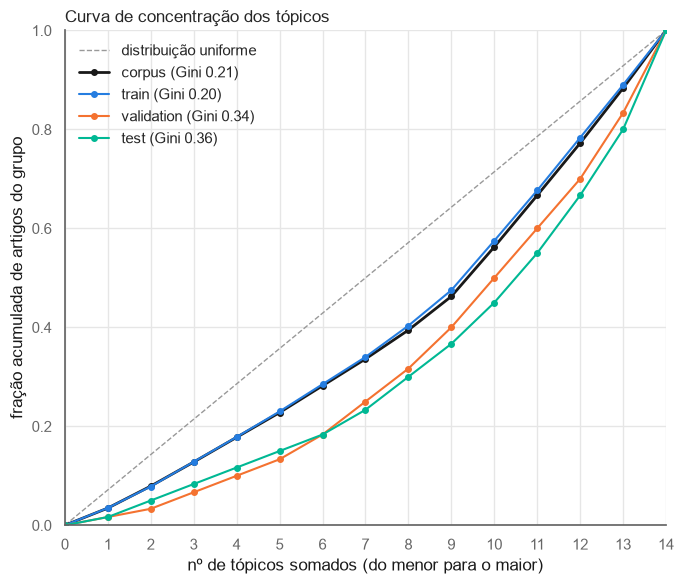

,artigos,Gini,entropia norm.,3 maiores tópicos
conjunto,,,,
corpus,720,0.213,0.972,0.333
train,600,0.203,0.974,0.323
validation,60,0.338,0.929,0.400
test,60,0.362,0.919,0.450


In [4]:
def curva_lorenz(contagens):
    p = np.sort(np.asarray(contagens, dtype=float)) / np.sum(contagens)
    x = np.linspace(0, 1, len(p) + 1)
    y = np.concatenate([[0], np.cumsum(p)])
    gini = 1 - np.sum((x[1:] - x[:-1]) * (y[1:] + y[:-1]))      # 1 − 2 × área sob a curva
    return x, y, gini

def entropia_norm(contagens):
    p = np.asarray(contagens, dtype=float)
    p = p[p > 0] / p.sum()
    return -(p * np.log2(p)).sum() / np.log2(len(contagens))

conjuntos_split = [("corpus", art, "#191919")] + [(s, art[art["split"] == s], c) for s, c in CORES.items()]

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, K], [0, 1], color="#999999", linestyle="--", linewidth=1, label="distribuição uniforme")
linhas = []
for nome, parte, cor in conjuntos_split:
    c = np.bincount(parte["topico"], minlength=K)
    x, y, gini = curva_lorenz(c)
    ax.plot(x * K, y, "o-", color=cor, markersize=4, linewidth=2 if nome == "corpus" else 1.5, label=f"{nome} (Gini {gini:.2f})")
    linhas.append({"conjunto": nome, "artigos": len(parte), "Gini": gini, "entropia norm.": entropia_norm(c),
                   "3 maiores tópicos": np.sort(c)[::-1][:3].sum() / c.sum()})
ax.set(xlabel="nº de tópicos somados (do menor para o maior)", ylabel="fração acumulada de artigos do grupo",
       xlim=(0, K), ylim=(0, 1), xticks=range(K + 1))
ax.set_title("Curva de concentração dos tópicos", loc="left")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()
pd.DataFrame(linhas).set_index("conjunto").round(3)

- O corpus e o train ficam perto da diagonal (Gini de 0,21 e 0,20): a distribuição é bem equilibrada, o que confirma a entropia normalizada de 0,97. Os 3 maiores tópicos têm 33% dos artigos, contra 21% se a distribuição fosse uniforme (3 de 14).
- Validation e test se afastam mais (Gini de 0,34 e 0,36), e no test os 3 maiores tópicos chegam a 45% dos artigos. Com só 60 artigos, o sorteio deixa a distribuição mais desigual: história militar tem 12 artigos no test, e vários tópicos têm só 1 ou 2.
- Ou seja, o corpus como um todo é equilibrado, mas o test, que é o split usado para avaliar modelos, é bem menos.

## 3. Existem grupos de artigos semanticamente semelhantes?

Para enxergar os 720 artigos de uma vez, reduzi os vetores de 384 dimensões para 2 com o **UMAP** (McInnes et al., 2018). Ele tenta manter perto, no plano, os artigos que estão perto no espaço original, ou seja, artigos com significado parecido. Usei a distância cosseno, a mesma das outras etapas.

Um cuidado na leitura: no UMAP, a **vizinhança** é confiável (quem está perto de quem), mas as **distâncias grandes** e o **tamanho** das manchas não têm significado exato. Por isso complemento com heatmaps da similaridade real.

In [5]:
xy = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=42).fit_transform(V)
art["x"], art["y"] = xy[:, 0], xy[:, 1]
print("UMAP pronto:", xy.shape)

C:\Users\jairoNeto\Desktop\kunumi\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


UMAP pronto: (720, 2)


**Gráfico 3.3** · Mapa semântico dos artigos

Este é o mapa principal da pergunta 3: cada artigo vira um ponto, e artigos com significado parecido ficam perto.

- cada ponto é um artigo, e a caixa com o nome de cada tópico fica na mediana das posições dos artigos dele. A cor é a mesma para todos os pontos; a separação por tópico aparece no próximo gráfico, com um painel para cada um.

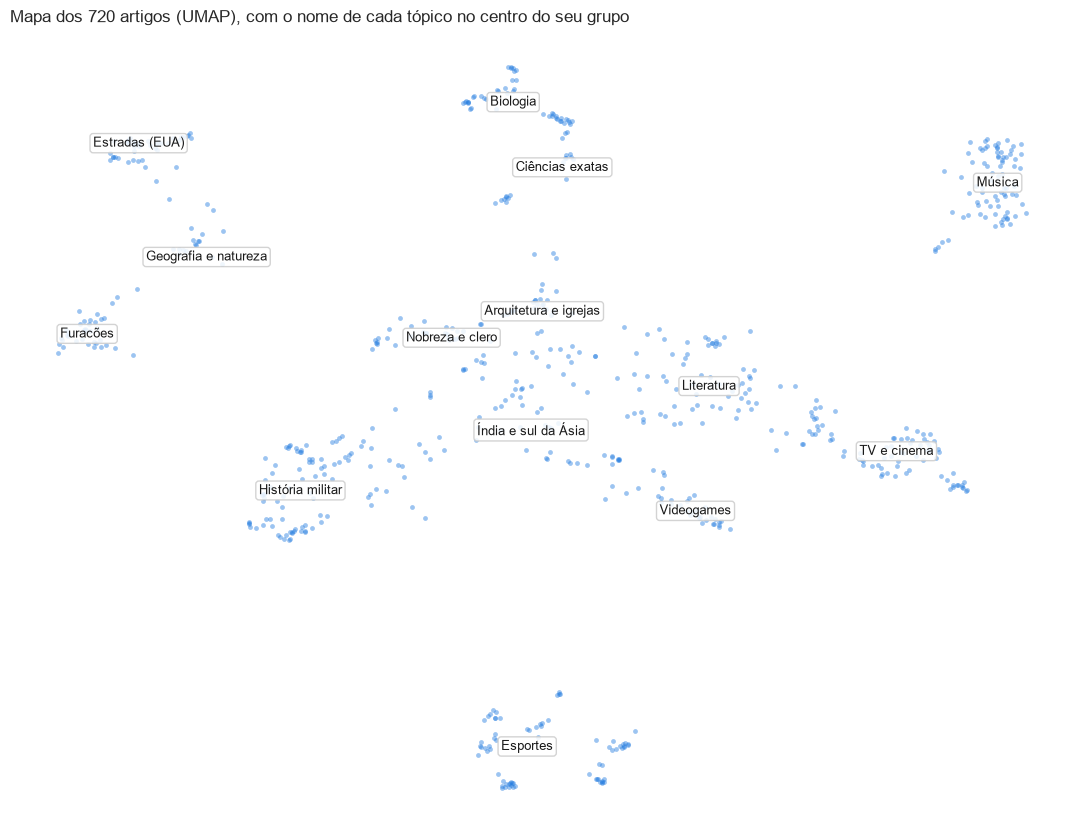

In [6]:
fig, ax = plt.subplots(figsize=(11, 8.5))
ax.scatter(art["x"], art["y"], s=12, color=AZUL, alpha=0.45, linewidths=0)
for nome, parte in art.groupby("tema"):
    cx, cy = parte["x"].median(), parte["y"].median()
    ax.text(cx, cy, nome, ha="center", va="center", fontsize=9, color="#191919",
            bbox=dict(facecolor="white", edgecolor="#cccccc", boxstyle="round,pad=0.25", alpha=0.85))
ax.set(xticks=[], yticks=[])
ax.spines[:].set_visible(False)
ax.grid(False)
ax.set_title("Mapa dos 720 artigos (UMAP), com o nome de cada tópico no centro do seu grupo", loc="left")
plt.tight_layout()
plt.show()

- Existem grupos bem separados: **esportes** forma uma ilha isolada lá embaixo (dividida em várias ilhotas), **música** forma outra no canto direito, e **biologia** fica no topo, perto de **ciências exatas**.
- À esquerda há uma faixa de assuntos do mundo físico: **estradas**, **geografia e natureza** e **furacões**, um ao lado do outro.
- No centro fica um "continente" de humanidades em que os tópicos se encostam: **nobreza e clero**, **arquitetura e igrejas**, **Índia**, **literatura**, **história militar**, **videogames** e **TV e cinema**. É aqui que aparece a silhueta baixa da Etapa 2: não há uma fronteira clara entre, por exemplo, literatura e TV e cinema.
- Algumas caixas caem num espaço vazio (como ciências exatas e geografia). Isso acontece quando o tópico está espalhado em mais de um lugar do mapa, e a mediana cai no meio do caminho.

**Gráfico 3.4** · Onde fica cada tópico no mapa

Como o mapa anterior usa uma cor só, aqui separo um painel por tópico para ver se cada um ocupa uma região própria ou se espalha. O último painel mostra os splits, para ver se validation e test ficam em regiões diferentes do train.

- em cada painel, os artigos do tópico estão em azul e o resto do corpus em cinza, sempre no mesmo mapa. No painel "por split", azul claro é train, laranja é validation e verde é test.

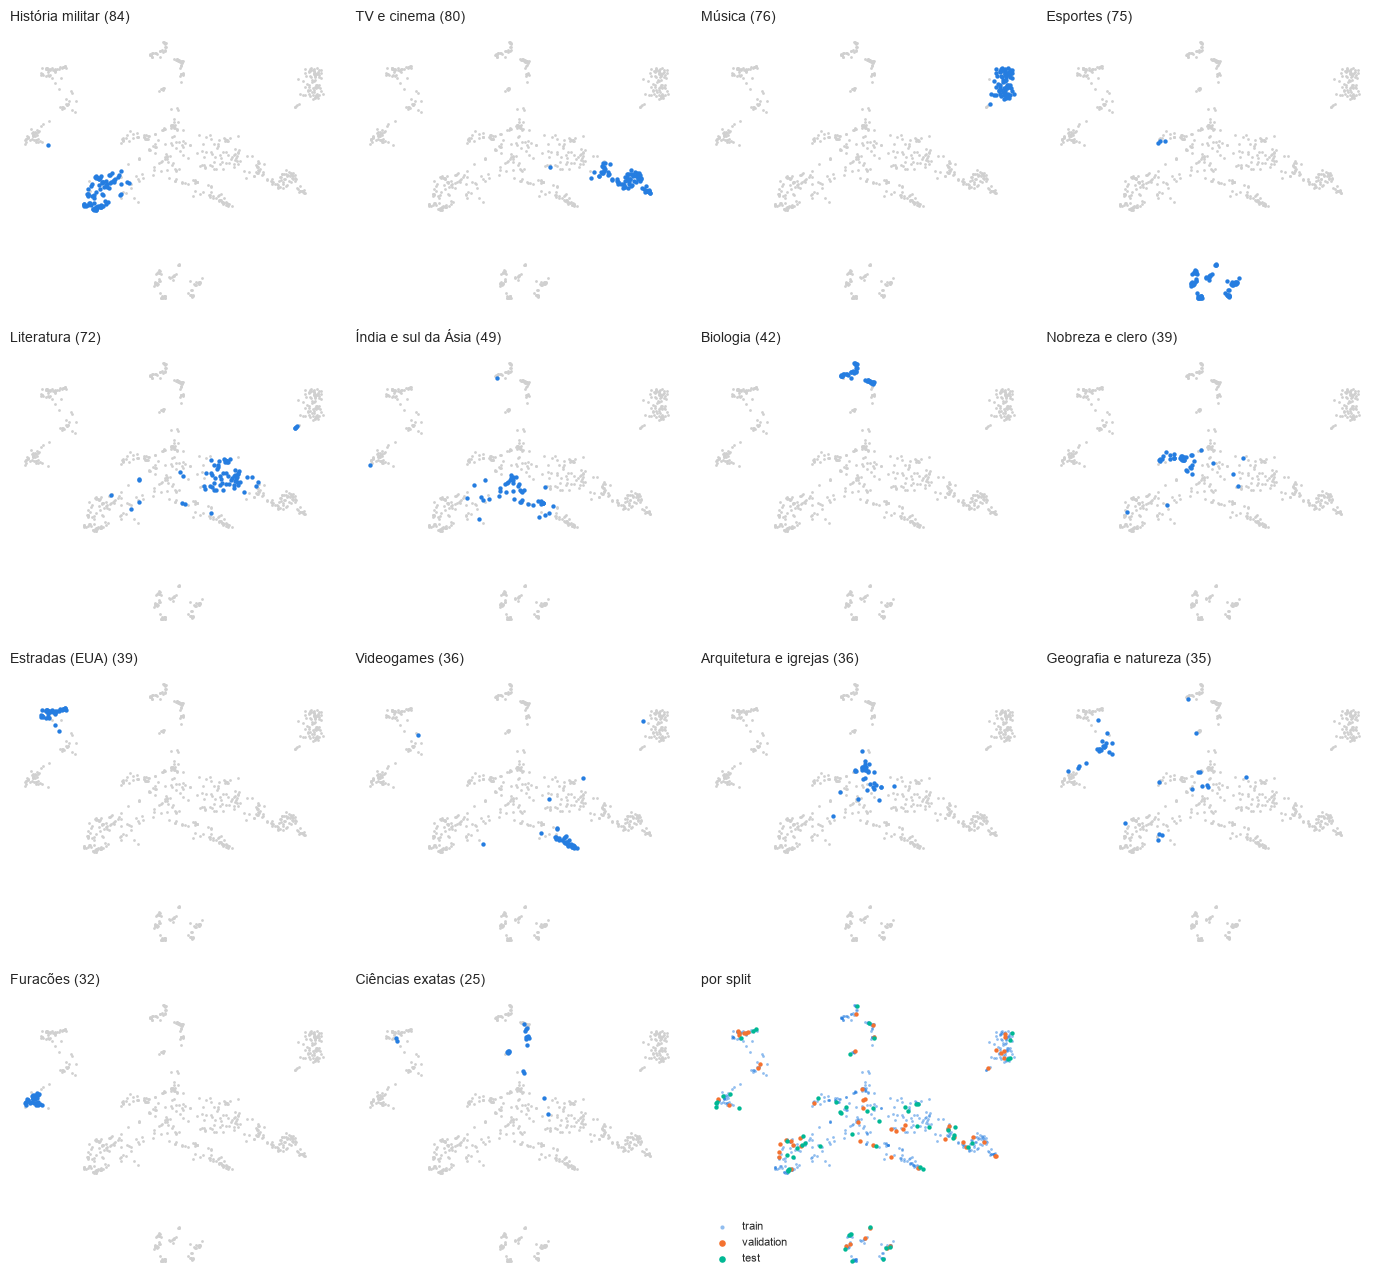

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(14, 13))
for ax, nome in zip(axes.flat, ORDEM_TAMANHO):
    dentro = art["tema"] == nome
    ax.scatter(art.loc[~dentro, "x"], art.loc[~dentro, "y"], s=4, color=CINZA, linewidths=0)
    ax.scatter(art.loc[dentro, "x"], art.loc[dentro, "y"], s=10, color=AZUL, linewidths=0)
    ax.set_title(f"{nome} ({dentro.sum()})", loc="left", fontsize=10)
ax = axes.flat[K]
for split, cor in CORES.items():
    parte = art[art["split"] == split]
    ax.scatter(parte["x"], parte["y"], s=4 if split == "train" else 10, color=cor, linewidths=0, label=split,
               alpha=0.5 if split == "train" else 1)
ax.set_title("por split", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, markerscale=1.5, loc="lower left")
for ax in axes.flat:
    ax.set(xticks=[], yticks=[])
    ax.spines[:].set_visible(False)
    ax.grid(False)
for ax in axes.flat[K + 1:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

- **Tópicos compactos**, que formam uma mancha única: música, esportes, furacões, estradas, biologia, TV e cinema e história militar.
- **Tópicos espalhados**, com artigos em várias regiões: Índia e sul da Ásia, geografia e natureza, ciências exatas e videogames. Por exemplo, alguns artigos de videogames aparecem perto de música e de estradas, e ciências exatas se divide entre a região de biologia e pontos soltos. Literatura também tem alguns artigos fora do seu núcleo.
- **Splits:** validation e test aparecem espalhados por todo o mapa, misturados com o train. Não existe uma região só do test, o que confirma o que vi na Etapa 2: os splits têm os mesmos tipos de assunto.

**Gráfico 3.5** · Similaridade real entre artigos e entre tópicos

O UMAP deforma as distâncias, então aqui volto para a similaridade cosseno de verdade, sem projeção. Quis ver se os tópicos aparecem como blocos de artigos parecidos e quais tópicos são vizinhos.

- na esquerda, cada pixel é a similaridade entre dois artigos (720 × 720), com os artigos ordenados por tópico; mais escuro quer dizer mais parecidos. Os tópicos estão em ordem "de parentesco": tópicos com centros parecidos ficam lado a lado. Na direita está a média dessa similaridade para cada par de tópicos. A diagonal é a similaridade dentro do tópico, e o resto, entre tópicos.

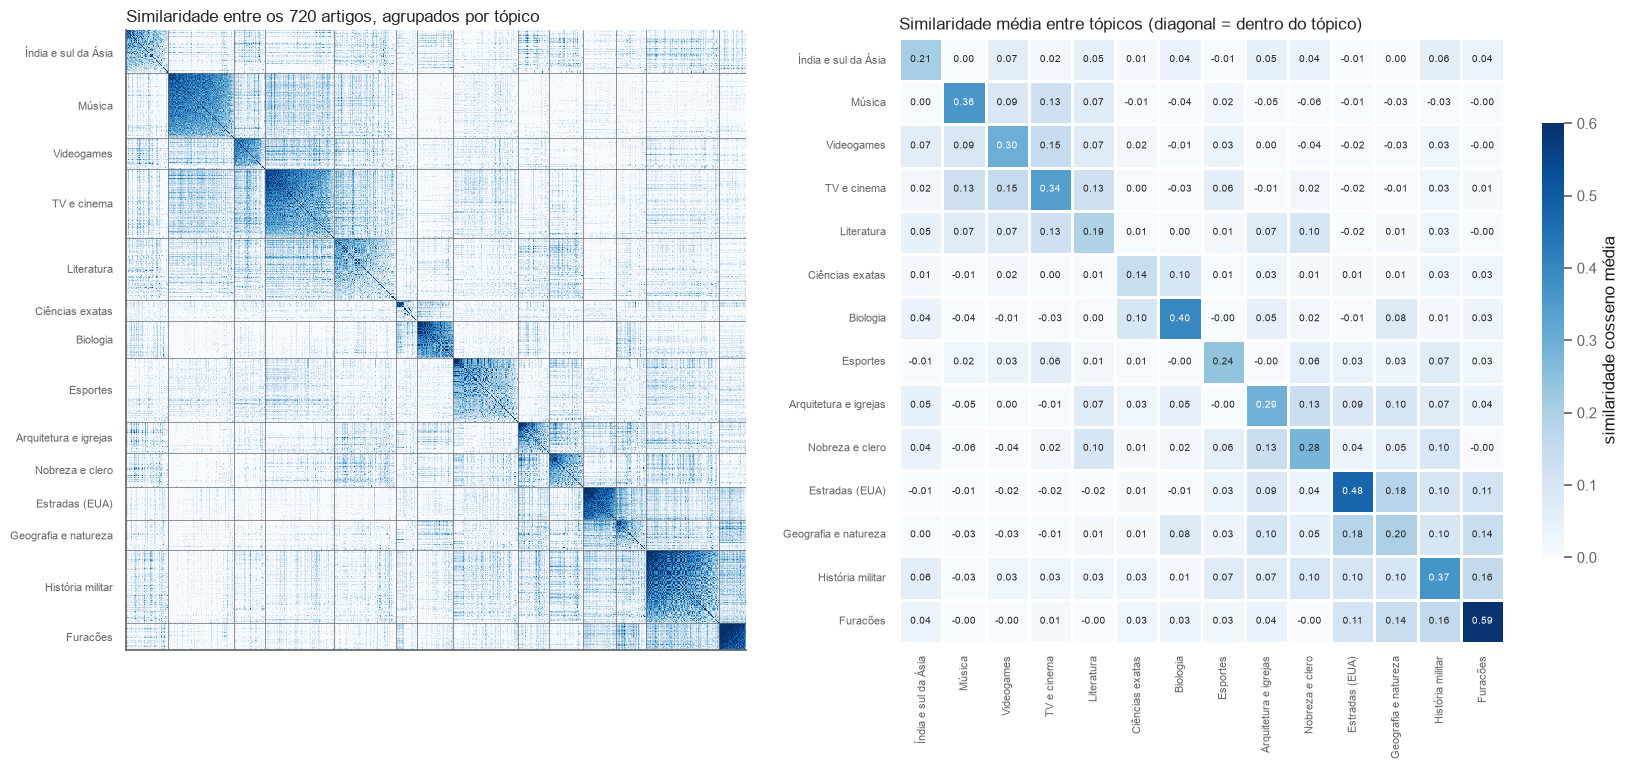

In [8]:
S = V @ V.T
pos = {n: i for i, n in enumerate(ORDEM_PARENTESCO)}
ordem_art = art.assign(o=art["tema"].map(pos)).sort_values(["o", "sim_centro"], ascending=[True, False]).index.to_numpy()

entre = pd.DataFrame(index=ORDEM_PARENTESCO, columns=ORDEM_PARENTESCO, dtype=float)
for a in ORDEM_PARENTESCO:
    ia = np.where(art["tema"] == a)[0]
    for b in ORDEM_PARENTESCO:
        ib = np.where(art["tema"] == b)[0]
        bloco = S[np.ix_(ia, ib)]
        entre.loc[a, b] = (bloco.sum() - len(ia)) / (len(ia) * (len(ia) - 1)) if a == b else bloco.mean()

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5), gridspec_kw={"width_ratios": [1, 1.15]})
axes[0].imshow(S[np.ix_(ordem_art, ordem_art)], cmap="Blues", vmin=0, vmax=0.6, interpolation="nearest")
tam = art["tema"].value_counts().reindex(ORDEM_PARENTESCO).to_numpy()
limites = np.concatenate([[0], np.cumsum(tam)])
for l in limites[1:-1]:
    axes[0].axhline(l - 0.5, color="#666666", linewidth=0.5)
    axes[0].axvline(l - 0.5, color="#666666", linewidth=0.5)
axes[0].set_yticks((limites[:-1] + limites[1:]) / 2 - 0.5, ORDEM_PARENTESCO, fontsize=8)
axes[0].set_xticks([])
axes[0].grid(False)
axes[0].set_title("Similaridade entre os 720 artigos, agrupados por tópico", loc="left")

sns.heatmap(entre, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=0.6, square=True, linewidths=1,
            linecolor="white", annot_kws={"fontsize": 7}, cbar_kws={"label": "similaridade cosseno média", "shrink": 0.7}, ax=axes[1])
axes[1].set_title("Similaridade média entre tópicos (diagonal = dentro do tópico)", loc="left")
axes[1].tick_params(axis="both", labelsize=8)
plt.tight_layout()
plt.show()

- Na esquerda aparecem **blocos escuros na diagonal**: dentro de cada tópico, os artigos são mais parecidos entre si do que com o resto. O bloco de furacões é o mais escuro, e o de ciências exatas quase não aparece.
- Fora da diagonal quase tudo é claro (perto de 0), com alguns retângulos mais azuis que mostram tópicos vizinhos. Na direita dá para ler quem são: estradas ↔ geografia (0,18), furacões ↔ história militar (0,16), TV e cinema ↔ videogames (0,15), arquitetura ↔ nobreza e clero (0,13) e música ↔ TV e cinema (0,13). São assuntos que dividem contexto: lugares; eventos com datas, danos e vítimas; mídia e entretenimento; Idade Média.
- A ordem de parentesco reproduz o mapa: os tópicos de cultura e mídia ficam no começo da lista, e os de lugares e eventos físicos, no fim.

## 4. O dataset apresenta diversidade lexical e temática?

A Etapa 2 respondeu isso com números para o corpus inteiro: MTLD mediano de 85,5, diversidade semântica de 0,94 entre artigos, 14 tópicos e entropia normalizada de 0,97. Aqui eu olho duas coisas que ainda faltavam: se essa diversidade é **igual nos três splits** e se ela é **igual dentro de cada tópico**.

**Gráfico 3.6** · A diversidade é igual nos três splits?

Na Etapa 2 eu vi as medianas por split numa tabela. Aqui quis ver a distribuição inteira, porque duas distribuições podem ter a mesma mediana e formatos bem diferentes.

- cada "violino" mostra a distribuição de uma medida num split: quanto mais largo, mais artigos com aquele valor. As linhas tracejadas são os quartis, e a do meio é a mediana.

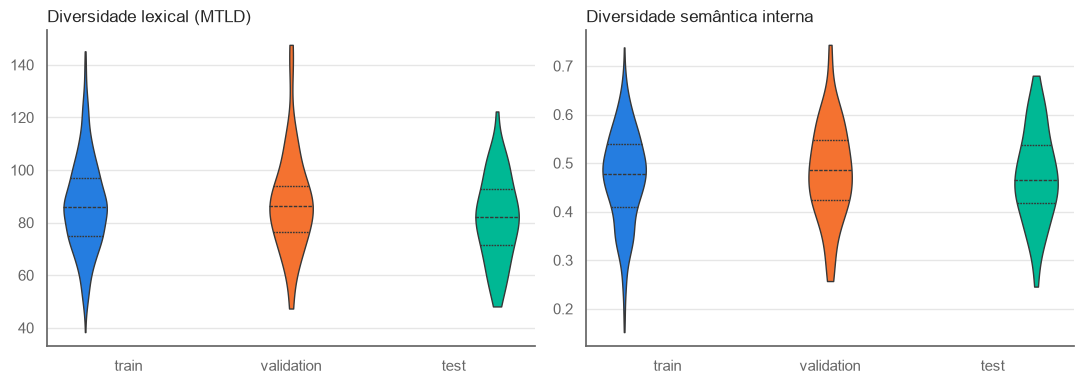

,mtld,div_semantica
split,,
train,85.784,0.478
validation,86.386,0.485
test,82.051,0.465


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, titulo in [(axes[0], "mtld", "Diversidade lexical (MTLD)"),
                        (axes[1], "div_semantica", "Diversidade semântica interna")]:
    sns.violinplot(data=art, x="split", y=col, hue="split", palette=CORES, legend=False, inner="quartile",
                   cut=0, linewidth=1, saturation=1, ax=ax)
    ax.set(xlabel="", ylabel="")
    ax.set_title(titulo, loc="left")
plt.tight_layout()
plt.show()
art.groupby("split", observed=True)[["mtld", "div_semantica"]].median().round(3)

- O MTLD tem formato e centro parecidos nos três splits (medianas de 86, 86 e 82). O test fica um pouco abaixo, mas dentro da variação esperada para 60 artigos.
- A diversidade semântica interna também é parecida (medianas de 0,48, 0,49 e 0,47).
- As pontas dos violinos variam porque os splits pequenos têm poucos artigos extremos, mas a parte central, entre os quartis, é praticamente a mesma.
- Então a diversidade lexical e a semântica interna são as mesmas nos três splits. O que muda entre eles é a mistura de assuntos (Gráfico 3.2), não o jeito de escrever.

**Gráfico 3.7** · Quais tópicos são mais fechados e quais são mais amplos?

A diversidade temática não depende só de quantos tópicos existem. Também importa o quanto cada tópico é variado por dentro: um tópico em que todos os artigos são parecidos traz menos diversidade do que um que cobre coisas bem diferentes.

- cada barra é a similaridade média entre os artigos de um mesmo tópico (a diagonal do Gráfico 3.5): quanto maior, mais parecidos os artigos entre si, ou seja, menos variado o tópico por dentro. Ao lado do nome está o tópico vizinho mais parecido. A linha tracejada é a similaridade média entre artigos de tópicos diferentes (0,04), como referência.

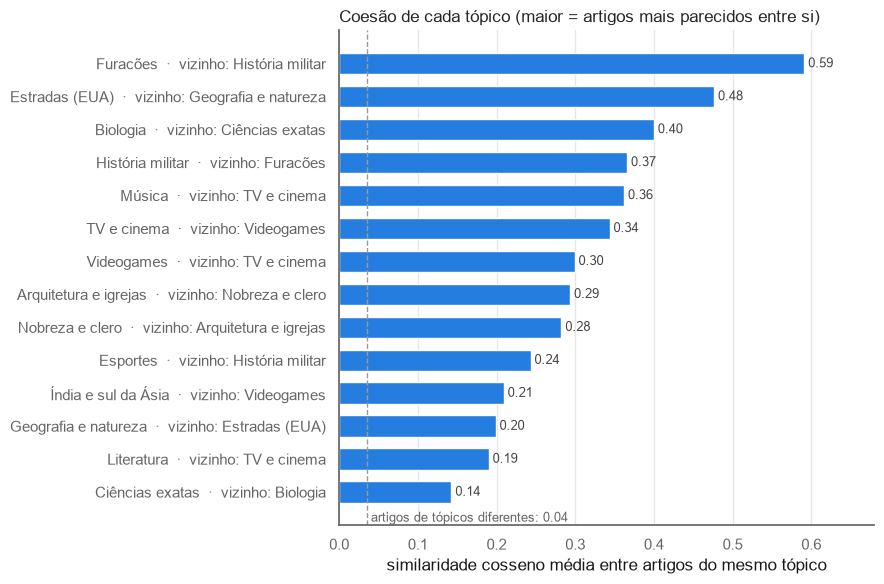

In [10]:
coesao = pd.Series(np.diag(entre.to_numpy()), index=entre.index)
vizinho = entre.where(~np.eye(K, dtype=bool)).idxmax(axis=1)
fora = S[np.triu_indices(len(S), k=1)][(art["topico"].to_numpy()[:, None] != art["topico"].to_numpy()[None, :])[np.triu_indices(len(S), k=1)]].mean()

ordem = coesao.sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh([f"{n}  ·  vizinho: {vizinho[n]}" for n in ordem.index], ordem.values, color=AZUL, height=0.65)
ax.axvline(fora, color="#999999", linestyle="--", linewidth=1)
ax.text(fora, -0.9, f" artigos de tópicos diferentes: {fora:.2f}", color="#666666", fontsize=9)
for y, v in enumerate(ordem.values):
    ax.text(v + 0.005, y, f"{v:.2f}", va="center", fontsize=9, color="#444444")
ax.set(xlabel="similaridade cosseno média entre artigos do mesmo tópico", xlim=(0, ordem.max() * 1.15))
ax.set_title("Coesão de cada tópico (maior = artigos mais parecidos entre si)", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

- **Furacões (0,59)** e **estradas (0,48)** são os tópicos mais fechados: os artigos seguem o mesmo molde (temporadas de furacões, trajetos de estradas). Eles têm 32 e 39 artigos, mas quase todos sobre a mesma coisa, então trazem pouca diversidade temática.
- **Ciências exatas (0,14)**, **literatura (0,19)**, **geografia e natureza (0,20)** e **Índia (0,21)** são os mais amplos: juntam assuntos diferentes num mesmo grupo (química, física e astronomia; escritores, obras e movimentos; rios, montanhas e cidades).
- Todos os tópicos ficam bem acima da linha de 0,04, então mesmo os mais amplos são grupos reais, e não artigos soltos.
- Isso mostra mais uma camada da diversidade temática: o equilíbrio entre os tópicos (entropia de 0,97) esconde que alguns deles são quase repetições de um mesmo molde.

## 5. Existem assuntos pouco representados?

O **Gráfico 2.7** mostra quantos **artigos** cada tópico tem e quantos caem em cada split. Mas, para um modelo de linguagem, o que pesa no treino é a quantidade de **texto**, não de artigos: um tópico com poucos artigos longos pode ter mais palavras que um tópico com muitos artigos curtos. Por isso aqui comparo a fração de artigos com a fração de palavras de cada tópico.

**Gráfico 3.8** · Quais assuntos têm pouco texto?

Na Etapa 2 eu contei artigos. Aqui quis ver quanto texto cada assunto realmente tem, porque um modelo de linguagem aprende com palavras, e não com artigos.

- cada linha é um tópico: o ponto azul é a fração dos artigos, e o laranja, a fração das palavras do corpus. Quando o laranja está à esquerda do azul, os artigos do tópico são mais curtos que a média; à direita, mais longos. A linha tracejada é a fração que cada tópico teria numa distribuição uniforme (7,1%).

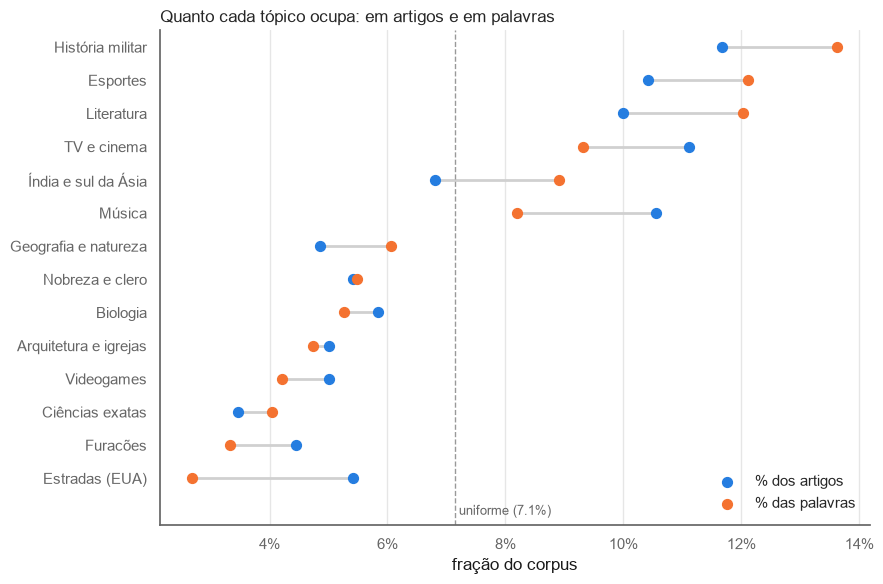

,artigos,palavras,val,test,% artigos,% palavras
tema,,,,,,
História militar,84,282815,8,12,11.7%,13.6%
Esportes,75,251394,6,8,10.4%,12.1%
Literatura,72,249614,5,7,10.0%,12.0%
TV e cinema,80,193362,10,6,11.1%,9.3%
Índia e sul da Ásia,49,184859,4,2,6.8%,8.9%
Música,76,170107,6,4,10.6%,8.2%
Geografia e natureza,35,125907,4,1,4.9%,6.1%
Nobreza e clero,39,113780,1,5,5.4%,5.5%
Biologia,42,109147,2,2,5.8%,5.3%


In [11]:
rep = art.groupby("tema").agg(artigos=("artigo", "size"), palavras=("n_tokens", "sum"),
                              val=("split", lambda s: (s == "validation").sum()), test=("split", lambda s: (s == "test").sum()))
rep["% artigos"] = rep["artigos"] / rep["artigos"].sum()
rep["% palavras"] = rep["palavras"] / rep["palavras"].sum()
rep = rep.sort_values("% palavras")

fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(rep))
ax.hlines(y, rep[["% artigos", "% palavras"]].min(axis=1), rep[["% artigos", "% palavras"]].max(axis=1), color=CINZA, linewidth=2)
ax.scatter(rep["% artigos"], y, color=AZUL, s=50, zorder=3, label="% dos artigos")
ax.scatter(rep["% palavras"], y, color=LARANJA, s=50, zorder=3, label="% das palavras")
ax.axvline(1 / K, color="#999999", linestyle="--", linewidth=1)
ax.text(1 / K, -1.1, f" uniforme ({1 / K:.1%})", color="#666666", fontsize=9)
ax.set_ylim(-1.4, len(rep) - 0.5)
ax.set_yticks(y, rep.index)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(xlabel="fração do corpus")
ax.set_title("Quanto cada tópico ocupa: em artigos e em palavras", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

rep.assign(**{"% artigos": rep["% artigos"].map("{:.1%}".format), "% palavras": rep["% palavras"].map("{:.1%}".format)})[::-1]

- **Estradas** é o caso mais forte: tem 5,4% dos artigos, mas só **2,7% das palavras**, porque seus artigos são curtos (mediana de 779 palavras). Furacões (4,4% → 3,3%), videogames, música e TV e cinema também têm menos texto do que o número de artigos sugere.
- No sentido contrário, **Índia** (6,8% → 8,9%), história militar, esportes, literatura e geografia têm artigos mais longos e ganham peso quando a conta é feita em palavras.
- Os menos representados em texto são **estradas (2,7%)**, **furacões (3,3%)** e **ciências exatas (4,0%)**, todos bem abaixo dos 7,1% de uma distribuição uniforme.
- No test a situação é mais extrema: vários tópicos têm só 1 ou 2 artigos (coluna `test` da tabela). Na prática, a nota de um modelo no test diz muito pouco sobre esses assuntos.

## 6. Como as métricas variam entre diferentes artigos ou grupos temáticos?

Na Etapa 2 eu vi como as métricas variam **entre artigos** (histogramas, extremos e correlações). Aqui eu olho a variação **entre tópicos**: se cada assunto tem um "perfil" próprio de tamanho, diversidade e complexidade.

**Gráfico 3.9** · As métricas mudam de um tópico para outro?

Até aqui eu olhei as métricas por artigo ou por split. Agora quis ver se cada assunto tem um jeito próprio de ser escrito: mais ou menos diverso, mais ou menos difícil, com artigos maiores ou menores.

- cada painel é uma métrica e cada caixa é um tópico: a linha no meio da caixa é a mediana, a caixa vai do 1º ao 3º quartil, e os pontos são artigos fora do comum. A linha tracejada é a mediana do corpus. Os tópicos estão na mesma ordem nos quatro painéis, do menor para o maior MTLD.

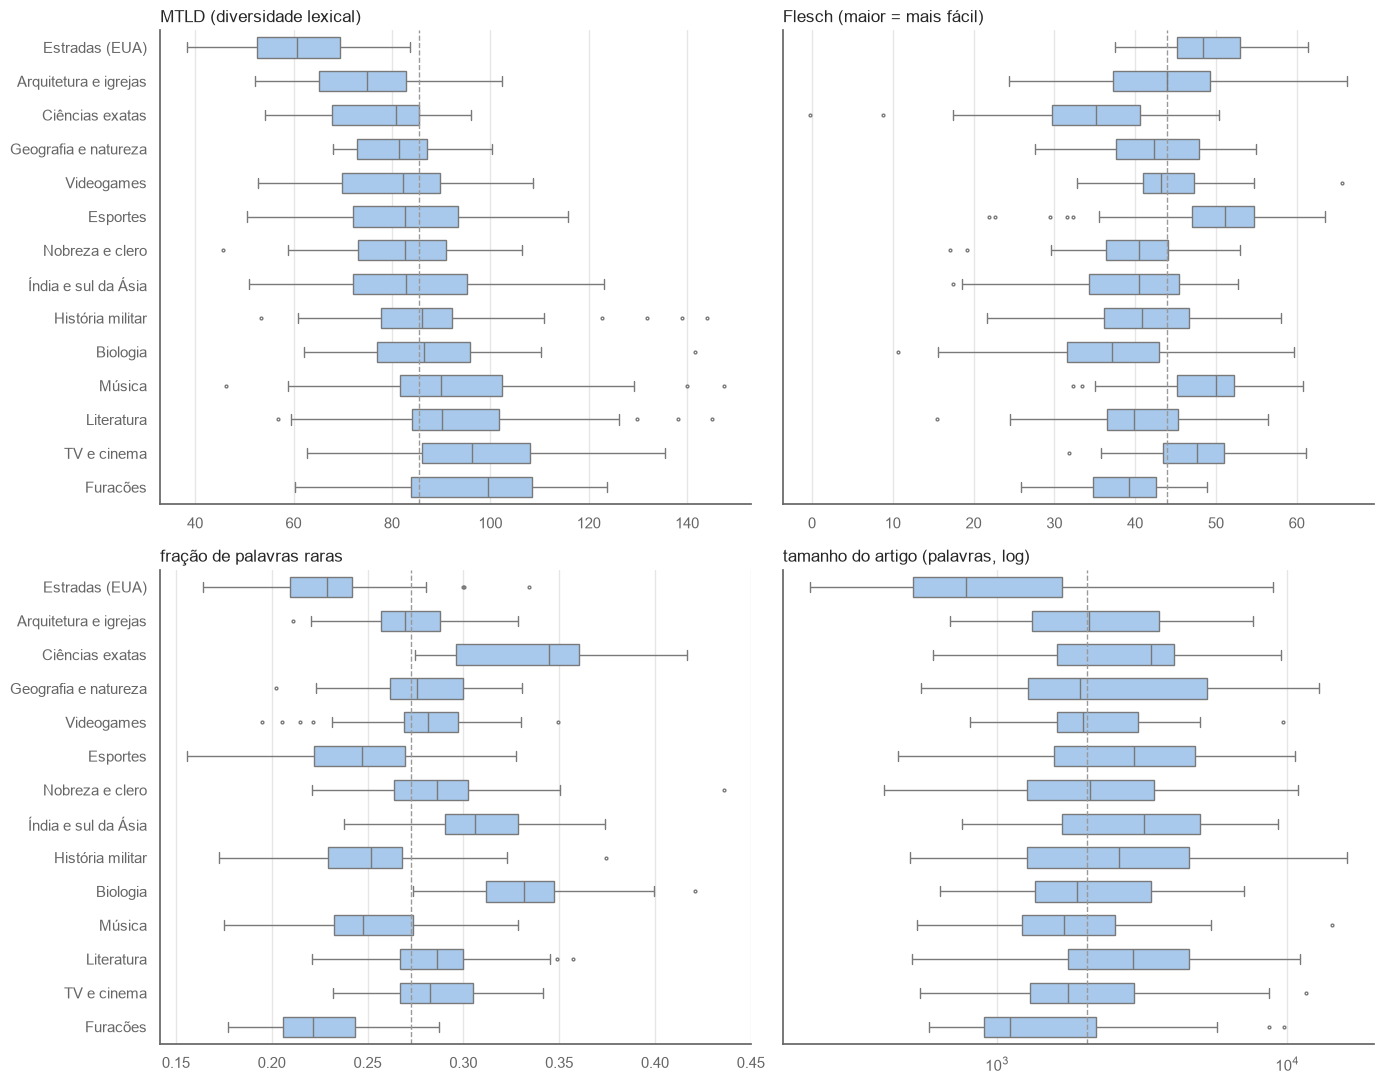

In [12]:
ordem_mtld = art.groupby("tema")["mtld"].median().sort_values().index.tolist()
paineis = [("mtld", "MTLD (diversidade lexical)", False), ("flesch", "Flesch (maior = mais fácil)", False),
           ("pct_raras", "fração de palavras raras", False), ("n_tokens", "tamanho do artigo (palavras, log)", True)]

fig, axes = plt.subplots(2, 2, figsize=(14, 11), sharey=True)
for ax, (col, titulo, log) in zip(axes.flat, paineis):
    sns.boxplot(data=art, y="tema", x=col, order=ordem_mtld, color="#9dc8f7", fliersize=2, width=0.6,
                linewidth=1, log_scale=log, ax=ax)
    ax.axvline(art[col].median(), color="#999999", linestyle="--", linewidth=1)
    ax.set(xlabel="", ylabel="")
    ax.set_title(titulo, loc="left")
plt.tight_layout()
plt.show()

- **MTLD:** estradas é claramente o tópico menos diverso (mediana de 61, contra 85 no corpus), seguido de arquitetura e igrejas (75). No outro extremo estão furacões (99), TV e cinema (96), literatura e música (~90).
- **Flesch:** ciências exatas (35) e biologia (37) são os mais difíceis, por causa das palavras técnicas. Esportes (51), música (50), TV e cinema e estradas (48) são os mais fáceis.
- **Palavras raras:** é onde os tópicos mais se separam. Ciências exatas (34%) e biologia (33%) usam muito mais vocabulário raro que furacões (22%), estradas (23%), esportes e música (25%).
- **Tamanho:** estradas e furacões têm os artigos mais curtos (medianas de 779 e 1.111 palavras), e ciências exatas e Índia, os mais longos (~3.300).
- As caixas se sobrepõem bastante: o tópico muda a mediana, mas dentro de cada tópico ainda existe muita variação.

**Gráfico 3.10** · O perfil de cada tópico

Os boxplots mostram quatro métricas. Aqui eu resumo oito numa figura só, para ver o "perfil" de cada tópico de uma vez.

- cada linha é um tópico e cada coluna, uma métrica. O número é a mediana do tópico, e a cor mostra o quanto essa mediana foge da média dos 14 tópicos, em desvios-padrão: vermelho = bem acima, azul = bem abaixo, cinza = na média. Os tópicos estão na ordem de parentesco do Gráfico 3.5.

Logo depois do gráfico, testo se essas diferenças entre tópicos podem ser só acaso, com o teste de **Kruskal-Wallis** (Kruskal & Wallis, 1952). Ele compara os grupos pelas posições (rankings) dos valores, sem supor distribuição normal, e responde se pelo menos um tópico tem valores sistematicamente diferentes dos outros. Junto, calculo o **tamanho do efeito ε²** (Tomczak & Tomczak, 2014), que vai de 0 a 1 e indica quanto da variação entre os artigos é explicada pelo tópico.

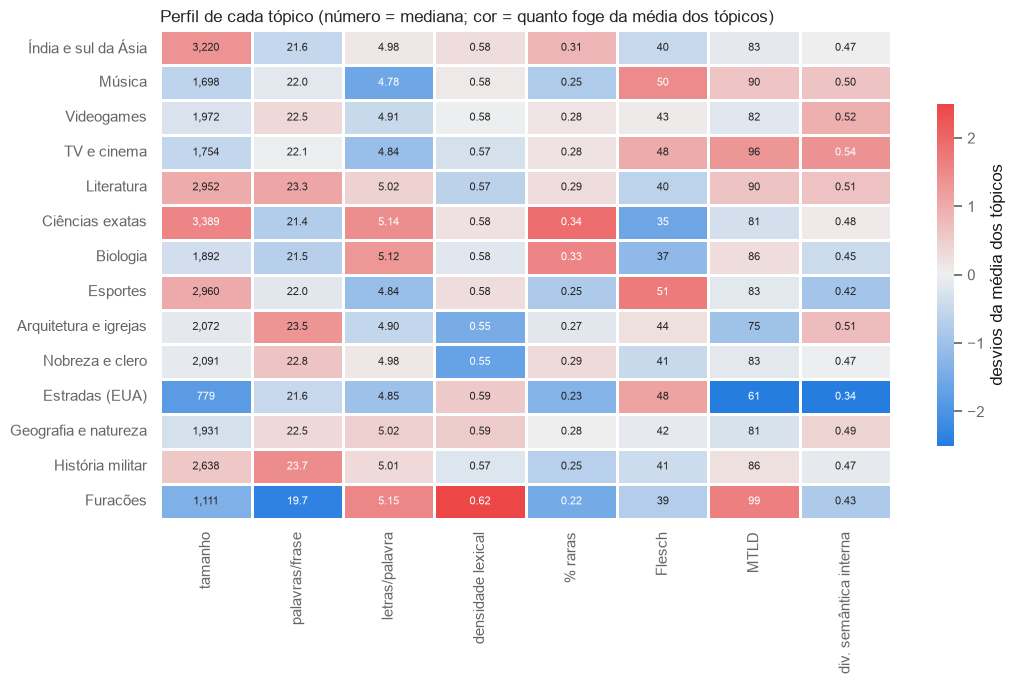

In [13]:
perfil_cols = {"n_tokens": "tamanho", "palavras_por_frase": "palavras/frase", "tam_palavra": "letras/palavra",
               "densidade_lexical": "densidade lexical", "pct_raras": "% raras", "flesch": "Flesch",
               "mtld": "MTLD", "div_semantica": "div. semântica interna"}
medianas = art.groupby("tema")[list(perfil_cols)].median().reindex(ORDEM_PARENTESCO)
z = (medianas - medianas.mean()) / medianas.std()
formatos = {"n_tokens": "{:,.0f}", "palavras_por_frase": "{:.1f}", "tam_palavra": "{:.2f}", "densidade_lexical": "{:.2f}",
            "pct_raras": "{:.2f}", "flesch": "{:.0f}", "mtld": "{:.0f}", "div_semantica": "{:.2f}"}
rotulos = medianas.apply(lambda col: col.map(formatos[col.name].format))

fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(z.rename(columns=perfil_cols), annot=rotulos.to_numpy(), fmt="", cmap=DIVERGENTE, vmin=-2.5, vmax=2.5,
            linewidths=1, linecolor="white", annot_kws={"fontsize": 8},
            cbar_kws={"label": "desvios da média dos tópicos", "shrink": 0.7}, ax=ax)
ax.set(xlabel="", ylabel="")
ax.set_title("Perfil de cada tópico (número = mediana; cor = quanto foge da média dos tópicos)", loc="left")
plt.tight_layout()
plt.show()

In [14]:
linhas = []
for col, nome in perfil_cols.items():
    grupos = [g[col].to_numpy() for _, g in art.groupby("tema")]
    H, p = kruskal(*grupos)
    linhas.append({"métrica": nome, "H": round(H, 1), "p": f"{p:.1e}", "efeito (ε²)": round(H / (len(art) - 1), 3)})
pd.DataFrame(linhas).set_index("métrica").sort_values("efeito (ε²)", ascending=False)

,H,p,efeito (ε²)
métrica,,,
% raras,327.600000,4.0e-62,0.456
Flesch,227.100000,3.6e-41,0.316
letras/palavra,180.400000,1.4e-31,0.251
MTLD,174.600000,2.1e-30,0.243
densidade lexical,162.600000,6.0e-28,0.226
div. semântica interna,160.899994,1.3e-27,0.224
tamanho,76.700000,4.5e-11,0.107
palavras/frase,76.900000,4.1e-11,0.107


- No perfil, alguns tópicos se destacam em várias colunas ao mesmo tempo:
  - **Estradas:** o mais curto (779 palavras), o menos diverso lexicalmente (MTLD de 61) e semanticamente (0,34), com poucas palavras raras. São textos curtos, repetitivos e de um assunto só.
  - **Ciências exatas e biologia:** muitas palavras raras (0,34 e 0,33), palavras longas e Flesch baixo (35 e 37). São os tópicos mais técnicos.
  - **Furacões:** as frases mais curtas (19,7 palavras), a maior densidade lexical (0,62) e o maior MTLD (99).
  - **Música e esportes:** os mais fáceis de ler (Flesch de 50 e 51), com palavras curtas e pouco vocabulário raro.
  - **TV e cinema:** a maior diversidade semântica interna (0,54), porque enredo, elenco, produção e recepção aparecem no mesmo artigo.
- No teste de Kruskal-Wallis, **todas as métricas variam de forma significativa entre os tópicos** (p < 10⁻¹⁰ em todas). O que muda é o tamanho do efeito:
  - **% de palavras raras (ε² = 0,46)** e **Flesch (0,32)** são as que mais dependem do assunto: só o tópico já explica quase metade da variação de vocabulário raro entre os artigos.
  - MTLD, letras por palavra, densidade lexical e diversidade semântica interna ficam no meio (de 0,22 a 0,25).
  - **Tamanho e palavras por frase (0,11)** são as que menos dependem do assunto: o tamanho de um artigo e o das suas frases variam quase tanto dentro de um tópico quanto entre tópicos.

**Checagem: os números inflam o MTLD?**

Uma coisa me chamou atenção no perfil: furacões é o tópico **mais fechado** (Gráfico 3.7, com artigos muito parecidos entre si) e, ao mesmo tempo, o de **maior MTLD**. Como na Etapa 1 eu decidi contar números como palavras, desconfiei que velocidades de vento, pressões e datas estivessem inflando a diversidade, já que cada número diferente conta como uma palavra nova. Para testar, recalculei o MTLD de cada artigo sem os tokens que têm dígitos e comparei a posição de cada tópico.

In [15]:
def mtld(tokens, limiar=0.72):
    def sentido(ts):
        fatores, tipos, n = 0, set(), 0
        for t in ts:
            n += 1
            tipos.add(t)
            if len(tipos) / n <= limiar:
                fatores, tipos, n = fatores + 1, set(), 0
        if n:
            fatores += (1 - len(tipos) / n) / (1 - limiar)
        return len(ts) / fatores
    return (sentido(tokens) + sentido(tokens[::-1])) / 2

tokens = textos.str.lower().str.findall(PALAVRA)
tem_digito = lambda t: any(ch.isdigit() for ch in t)
art["pct_numeros"] = tokens.map(lambda ts: np.mean([tem_digito(t) for t in ts]))
art["mtld_sem_numeros"] = tokens.map(lambda ts: mtld([t for t in ts if not tem_digito(t)]))

tab = art.groupby("tema")[["pct_numeros", "mtld", "mtld_sem_numeros"]].median()
tab["posição com números"] = tab["mtld"].rank(ascending=False).astype(int)
tab["posição sem números"] = tab["mtld_sem_numeros"].rank(ascending=False).astype(int)
tab.sort_values("mtld", ascending=False).round(3)

,pct_numeros,mtld,mtld_sem_numeros,posição com números,posição sem números
tema,,,,,
Furacões,0.058,99.472,82.159,1,4
TV e cinema,0.015,96.267,92.574,2,1
Literatura,0.020,90.133,84.767,3,3
Música,0.028,89.908,84.782,4,2
Biologia,0.026,86.439,81.398,5,5
História militar,0.053,86.104,71.725,6,11
Índia e sul da Ásia,0.028,82.968,76.515,7,7
Nobreza e clero,0.025,82.652,75.631,8,8
Esportes,0.056,82.624,72.511,9,10


- Furacões é um dos tópicos com mais números (5,8% das palavras), junto com estradas (7,8%), esportes (5,6%) e história militar (5,3%). Nos tópicos de cultura, como TV e cinema (1,5%) e literatura (2,0%), eles são raros.
- Sem os números, o MTLD dos furacões cai de 99 para 82, e o tópico passa do **1º para o 4º lugar**. História militar cai do 6º para o 11º. TV e cinema, que quase não tem números, passa a ser o tópico mais diverso.
- Então parte da diversidade lexical de furacões e de história militar vem dos números, e não do vocabulário. É uma limitação da tokenização que escolhi na Etapa 1: contar números como palavras preserva o texto original, mas faz o MTLD premiar textos cheios de datas e medidas.
- Estradas continua em último com ou sem números, então a baixa diversidade lexical dele é real.

**Gráfico 3.11** · Onde ficam os artigos mais diversos e mais difíceis no mapa?

Para fechar, pintei o mapa do Gráfico 3.3 com duas métricas, para ver se a diversidade e a dificuldade se concentram em regiões de assunto ou se espalham pelo mapa todo.

- é o mesmo mapa UMAP, com cada artigo colorido pelo seu valor. Na esquerda está o MTLD (azul mais escuro = mais diverso) e, na direita, o Flesch (laranja mais escuro = mais difícil). As cores vão do 2º ao 98º percentil, para um artigo extremo não "apagar" o resto.

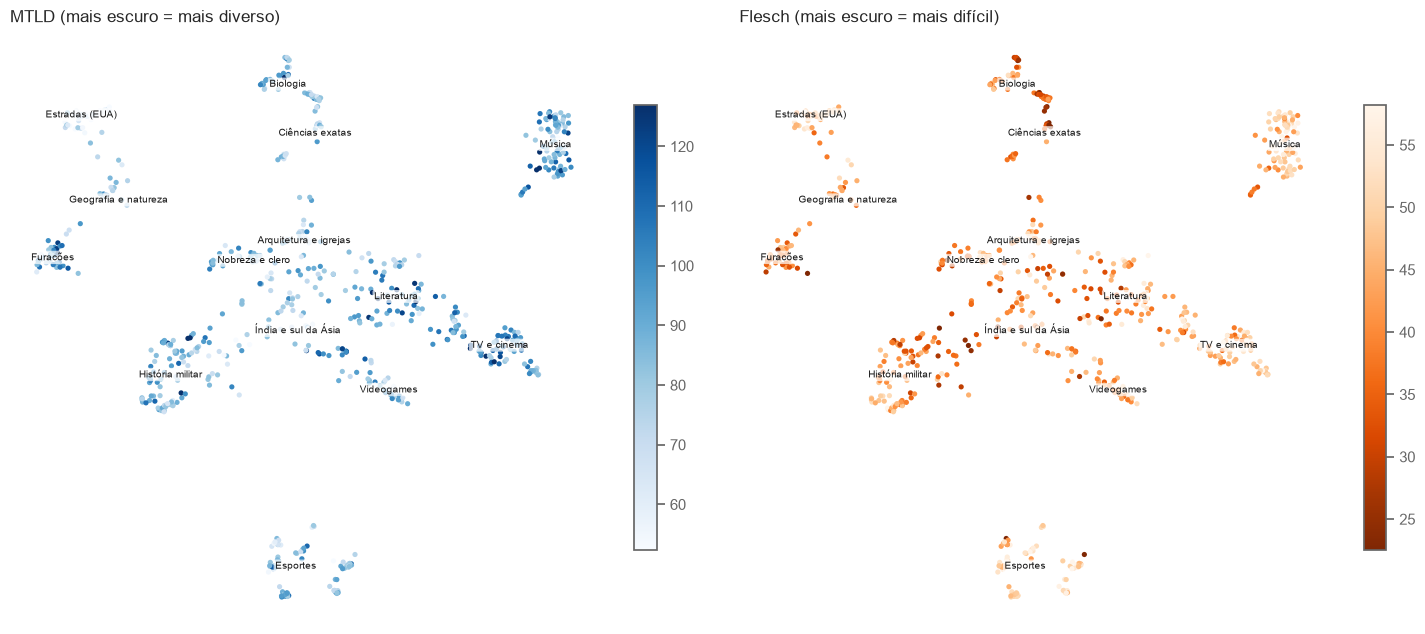

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, col, cmap, titulo in [(axes[0], "mtld", "Blues", "MTLD (mais escuro = mais diverso)"),
                              (axes[1], "flesch", "Oranges_r", "Flesch (mais escuro = mais difícil)")]:
    pts = ax.scatter(art["x"], art["y"], c=art[col], cmap=cmap, s=14, linewidths=0,
                     vmin=art[col].quantile(0.02), vmax=art[col].quantile(0.98))
    for nome, parte in art.groupby("tema"):
        ax.text(parte["x"].median(), parte["y"].median(), nome, ha="center", va="center", fontsize=7.5, color="#191919",
                bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.15", alpha=0.7))
    fig.colorbar(pts, ax=ax, shrink=0.75)
    ax.set(xticks=[], yticks=[])
    ax.spines[:].set_visible(False)
    ax.grid(False)
    ax.set_title(titulo, loc="left")
plt.tight_layout()
plt.show()

- **A dificuldade (Flesch) tem região:** o laranja escuro se concentra em biologia e ciências exatas, no topo, e aparece bastante no centro (história militar, nobreza, Índia). Música, esportes e TV e cinema ficam claros, ou seja, mais fáceis.
- **A diversidade (MTLD) também tem região, mas é mais misturada:** música, TV e cinema e furacões ficam mais escuros, e estradas fica claro. Mesmo assim, em quase todas as regiões há artigos claros e escuros lado a lado.
- Isso bate com o Kruskal-Wallis: o assunto pesa mais na dificuldade (ε² = 0,32 para o Flesch) do que na diversidade lexical (0,24 para o MTLD).

## Respostas às perguntas

**1. Quais são os assuntos mais frequentes no WikiText-2?** História militar (84 artigos), TV e cinema (80), música (76), esportes (75) e literatura (72), que juntos somam 54% do corpus (Gráfico 2.7). As palavras-chave confirmam do que cada um fala (Gráfico 3.1).

**2. Como os diferentes assuntos estão distribuídos?** De forma equilibrada no corpus (Gini de 0,21 e entropia normalizada de 0,97), mas bem menos no validation e no test (Gini de 0,34 e 0,36), que têm só 60 artigos (Gráfico 3.2). Em quantidade de texto, a distribuição muda: tópicos de artigos curtos, como estradas, perdem peso (Gráfico 3.8).

**3. Existem grupos de artigos semanticamente semelhantes?** Sim. Esportes, música e biologia formam ilhas separadas no mapa; estradas, geografia e furacões formam uma faixa de assuntos do mundo físico; e os tópicos de humanidades se encostam num grande grupo central (Gráficos 3.3 e 3.4). Dentro de cada tópico, os artigos são bem mais parecidos entre si do que com os de fora, e os tópicos vizinhos fazem sentido, como estradas ↔ geografia e TV e cinema ↔ videogames (Gráfico 3.5).

**4. O dataset apresenta diversidade lexical e temática?** Sim, e de forma parecida nos três splits (Gráfico 3.6). Mas a diversidade temática tem duas camadas: os tópicos são equilibrados entre si, porém alguns são quase repetições de um mesmo molde (furacões e estradas), enquanto outros juntam coisas bem diferentes (ciências exatas e literatura) (Gráfico 3.7).

**5. Existem assuntos pouco representados?** Sim. Em palavras, estradas (2,7%), furacões (3,3%) e ciências exatas (4,0%) ficam bem abaixo dos 7,1% de uma distribuição uniforme (Gráfico 3.8), e no test vários tópicos têm só 1 ou 2 artigos. Além disso, assuntos como medicina, economia e tecnologia nem chegam a formar tópico, porque o WikiText-2 só tem artigos *Good* e *Featured* da Wikipédia.

**6. Como as métricas variam entre diferentes artigos ou grupos temáticos?** Todas as métricas variam de forma significativa entre os tópicos, mas com intensidades diferentes (Gráficos 3.9 e 3.10). O assunto explica muito do vocabulário técnico (% de palavras raras, ε² = 0,46) e da dificuldade de leitura (Flesch, 0,32), e pouco do tamanho dos artigos e das frases (0,11). Ciências exatas e biologia são os tópicos mais técnicos, e estradas é o mais curto e repetitivo. A dificuldade se concentra em regiões do mapa, e a diversidade lexical é mais misturada (Gráfico 3.11). Por fim, a checagem dos números mostrou que parte do MTLD alto de furacões e de história militar vem de datas e medidas, uma limitação da tokenização.